<a href="https://colab.research.google.com/github/mhage82/ARI510/blob/main/notebooks/lab1_starter_mohammad_hassan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARI 410/510 — Lab 1 Starter Notebook

*AI Disclosure: Claude Opus 4.8 was used to generate the initial version of this notebook.*

This notebook gets you off the ground: it **loads the data**, **cleans it**, makes a **train / dev / test split**, and runs **one $k$-NN model**.

**How to use this:** In Colab, go to *File → Save a copy in Drive* and work in your copy. Then run the cells top to bottom, read the comments, and build from the `# YOUR TURN` sections.

The choices made here (how to handle missing values, how to encode categories, the split sizes) are **reasonable starting points, not the only right answers** — you're encouraged to change them and say why in your report.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

## 1. Load the data

Download `heart_disease_uci.csv` from Canvas (or Kaggle) and get it into this notebook.

- **In Colab:** run the cell below and pick the file from your computer, **or** upload it to the file panel on the left and skip the upload cell.
- **Locally (Jupyter):** just put the CSV next to this notebook.


In [2]:
# --- Colab upload (skip if you added the file another way) ---
try:
    import google.colab
    from google.colab import files
    uploaded = files.upload()   # choose heart_disease_uci.csv
except ImportError:
    pass  # not on Colab; assume the file is alongside the notebook

In [3]:
df = pd.read_csv('heart_disease_uci.csv')
print(df.shape)
df.head()

(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [6]:
# Quick look: column types and how many values are missing
df.info()
print('\nMissing values per column:')
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB

Missing values per column:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol    

## 2. Define the label and the features

The raw target `num` runs from 0 to 4 (0 = no disease, 1–4 = increasing severity). For this lab we treat it as a **binary** problem: disease present (1) vs. absent (0). You could instead keep it multi-class — that's a design choice you can revisit.


In [25]:
# Binary label: 1 if any disease is present, else 0
y = (df['num'] > 0).astype(int)
print(y.value_counts())

# Features: drop the id and the raw target. (You might also experiment with
# dropping 'dataset', which records the source hospital.)
X = df.drop(columns=['id', 'num', 'dataset'])
X.head()

num
1    509
0    411
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal


## 3. Data Analysis
This section is analyzing the data to find missing values and look for potential solutions to replace them in the training data

In [26]:
print("Missing values per feature with descending order:")
print(X.isna().sum().sort_values(ascending=False))
for col in X.columns:
    if X[col].eq(0).any():
        print(f"Column '{col}' has {X[col].eq(0).sum()} zero values.")

Missing values per feature with descending order:
ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
thalch       55
exang        55
chol         30
restecg       2
sex           0
age           0
cp            0
dtype: int64
Column 'trestbps' has 1 zero values.
Column 'chol' has 172 zero values.
Column 'fbs' has 692 zero values.
Column 'exang' has 528 zero values.
Column 'oldpeak' has 370 zero values.
Column 'ca' has 181 zero values.


## 4. Train / dev / test split

Three sets, not two:
- **train** — fit the models on this.
- **dev** — compare your configurations on this while you tune.
- **test** — *touch this only once*, at the very end, for your final numbers.

We use a 60 / 20 / 20 split, stratified so each set keeps the same class balance.


In [75]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(f'train: {len(X_train)}   dev: {len(X_dev)}   test: {len(X_test)}')
print(f"training data header is \n {X_train.head(10)}")

train: 552   dev: 184   test: 184
training data header is 
      age     sex              cp  trestbps   chol    fbs           restecg  \
904   57    Male    asymptomatic     130.0  207.0  False  st-t abnormality   
726   65    Male    asymptomatic     150.0  236.0   True  st-t abnormality   
145   47    Male     non-anginal     108.0  243.0  False            normal   
10    57    Male    asymptomatic     140.0  192.0  False            normal   
710   67    Male  typical angina     145.0    0.0  False    lv hypertrophy   
508   47    Male    asymptomatic     150.0  226.0  False            normal   
499   38    Male    asymptomatic      92.0  117.0  False            normal   
704   65    Male    asymptomatic     115.0    0.0  False            normal   
689   62  Female  typical angina     140.0    0.0    NaN            normal   
54    60    Male    asymptomatic     130.0  253.0  False            normal   

     thalch  exang  oldpeak      slope   ca               thal  
904    96.0   Tr

## 5. Data Preprocessing
The training data will be used to fill the missing values, encoding categorical features, and the scaling of data.
The filled numbers in the training data will be applied to the dev and test data

In [76]:
def mark_invalid_values_as_missing(features):
    replaced = features.copy()

    # Replace invalid values with NaN
    replaced["chol"] = replaced["chol"].replace(0, np.nan)
    replaced["trestbps"] = replaced["trestbps"].replace(0, np.nan)

    return replaced

X_train_replaced = mark_invalid_values_as_missing(X_train)
X_dev_replaced = mark_invalid_values_as_missing(X_dev)
X_test_replaced = mark_invalid_values_as_missing(X_test)

numeric_features = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]

categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

# for all numeric features, we replace the missing values with the median of the training set
# print(f"X_train_replaced before imputation:\n{X_train_replaced[numeric_features].isna().sum()}\n")
# print(f"X_dev_replaced before imputation:\n{X_dev_replaced[numeric_features].isna().sum()}\n")
# print(f"X_test_replaced before imputation:\n{X_test_replaced[numeric_features].isna().sum()}\n")
for col in numeric_features:
    col_median = X_train_replaced[col].median()
    X_train_replaced[col] = X_train_replaced[col].fillna(col_median)
    X_dev_replaced[col] = X_dev_replaced[col].fillna(col_median)
    X_test_replaced[col] = X_test_replaced[col].fillna(col_median)

# print(f"X_train_replaced after imputation:\n{X_train_replaced[numeric_features].isna().sum()}\n")
# print(f"X_dev_replaced after imputation:\n{X_dev_replaced[numeric_features].isna().sum()}\n")
# print(f"X_test_replaced after imputation:\n{X_test_replaced[numeric_features].isna().sum()}\n")

from sklearn.preprocessing import OneHotEncoder

# replace missing categorical data with "missing" string
for col in categorical_features:
    X_train_replaced[col] = X_train_replaced[col].fillna('missing').astype(str)
    X_dev_replaced[col] = X_dev_replaced[col].fillna('missing').astype(str)
    X_test_replaced[col] = X_test_replaced[col].fillna('missing').astype(str)
# print(X_train_replaced.head(10))

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoder.fit(X_train_replaced[categorical_features])

X_train_encoded = encoder.transform(X_train_replaced[categorical_features])
X_dev_encoded = encoder.transform(X_dev_replaced[categorical_features])
X_test_encoded = encoder.transform(X_test_replaced[categorical_features])

# print(X_train_encoded[:10])

X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_features), index=X_train_replaced.index)
X_dev_encoded_df = pd.DataFrame(X_dev_encoded, columns=encoder.get_feature_names_out(categorical_features), index=X_dev_replaced.index)
X_test_encoded_df = pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_features), index=X_test_replaced.index)

X_train_final = pd.concat([X_train_replaced[numeric_features], X_train_encoded_df], axis=1)
X_dev_final = pd.concat([X_dev_replaced[numeric_features], X_dev_encoded_df], axis=1)
X_test_final = pd.concat([X_test_replaced[numeric_features], X_test_encoded_df], axis=1)

print(f"X_train_final:\n {X_train_final.head(10)} \n")
# print(f"X_dev_final:\n {X_dev_final.head(10)} \n")
# print(f"X_test_final:\n {X_test_final.head(10)} \n")



X_train_final:
      age  trestbps   chol  thalch  oldpeak   ca  sex_Female  sex_Male  \
904   57     130.0  207.0    96.0      1.0  0.0         0.0       1.0   
726   65     150.0  236.0   105.0      0.0  0.0         0.0       1.0   
145   47     108.0  243.0   152.0      0.0  0.0         0.0       1.0   
10    57     140.0  192.0   148.0      0.4  0.0         0.0       1.0   
710   67     145.0  239.0   125.0      0.0  0.0         0.0       1.0   
508   47     150.0  226.0    98.0      1.5  0.0         0.0       1.0   
499   38      92.0  117.0   134.0      2.5  0.0         0.0       1.0   
704   65     115.0  239.0    93.0      0.0  0.0         0.0       1.0   
689   62     140.0  239.0   143.0      0.0  0.0         1.0       0.0   
54    60     130.0  253.0   144.0      1.4  1.0         0.0       1.0   

     cp_asymptomatic  cp_atypical angina  ...  exang_True  exang_missing  \
904              1.0                 0.0  ...         1.0            0.0   
726              1.0        

## 6. One example model: $k$-NN

$k$-NN compares a new point to its nearest neighbors, so the **scale** of each feature matters (a feature measured in the hundreds would otherwise dominate one measured 0–1). We put a `StandardScaler` in a `Pipeline` with the classifier so scaling is fit on the training data only.

We evaluate on the **dev** set — not the test set.


In [58]:
k_values = [1, 3, 5, 7, 9, 25,50,101,201]
knn_results = []
for k in k_values:
    knn = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k)),
    ])
    knn.fit(X_train_final, y_train)

    dev_pred = knn.predict(X_dev_final)
    knn_results.append({
        "k": k,
        "recall": recall_score(y_dev, dev_pred),
        "precision": precision_score(y_dev, dev_pred),
        "f1": f1_score(y_dev, dev_pred),
        "accuracy": accuracy_score(y_dev, dev_pred)
    })
knn_results_df = pd.DataFrame(knn_results)
knn_results_df = knn_results_df.sort_values(by=["recall", "precision"],
                                            ascending=[False, False])
knn_results_df.style.hide(axis="index")


k,recall,precision,f1,accuracy
25,0.872549,0.855769,0.864078,0.847826
50,0.833333,0.876289,0.854271,0.842391
9,0.833333,0.858586,0.845771,0.831522
101,0.833333,0.850000,0.841584,0.826087
3,0.833333,0.841584,0.837438,0.820652
5,0.833333,0.841584,0.837438,0.820652
201,0.823529,0.848485,0.835821,0.820652
7,0.823529,0.831683,0.827586,0.809783
1,0.794118,0.801980,0.798030,0.777174


## 7. YOUR TURN

Everything above is the scaffold. The actual lab is here.

**Run the comparison for your track:**
- **410:** run $k$-NN, logistic regression, and SVM across the specific hyperparameter settings in the assignment (at least 15 runs), evaluating each on the **dev** set. Then take the best of each and evaluate **once** on the **test** set.
- **510:** design your own comparison across at least five classifiers of your choice.

Useful imports:
```python
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
```
Every model can go in the same `Pipeline([('scale', StandardScaler()), ('model', ...)])` pattern used above.


In [66]:
from sklearn.linear_model import LogisticRegression

c_values = [0.01, 0.1, 1, 10, 100]

logistic_results = []
for c in c_values:
    logistic_model = Pipeline([
        ('scale', StandardScaler()),
        ('logistic', LogisticRegression(C=c, max_iter=1000)),
    ])
    logistic_model.fit(X_train_final, y_train)

    dev_pred = logistic_model.predict(X_dev_final)
    logistic_results.append({
        "C": c,
        "recall": recall_score(y_dev, dev_pred),
        "precision": precision_score(y_dev, dev_pred),
        "f1": f1_score(y_dev, dev_pred),
        "accuracy": accuracy_score(y_dev, dev_pred)
    })
logistic_results = pd.DataFrame(logistic_results)
logistic_results = logistic_results.sort_values(by=["recall", "precision"],
                                            ascending=[False, False])
print("\nlogistic_results are:\n")
logistic_results.style.hide(axis="index")

from sklearn.svm import SVC

kernels = ['linear','rbf']
c_values = [0.01, 0.1, 1, 10, 100]
svm_results = []
for kernel in kernels:  
    for c in c_values:
        svm_model = Pipeline([
            ('scale', StandardScaler()),
            ('svm', SVC(kernel=kernel, C=c, gamma='scale')),
        ])
        svm_model.fit(X_train_final, y_train)

        dev_pred = svm_model.predict(X_dev_final)
        svm_results.append({
            "kernel": kernel,
            "C": c,
            "recall": recall_score(y_dev, dev_pred),
            "precision": precision_score(y_dev, dev_pred),
            "f1": f1_score(y_dev, dev_pred),
            "accuracy": accuracy_score(y_dev, dev_pred)
        })

svm_results_df = pd.DataFrame(svm_results)
svm_results_df = svm_results_df.sort_values(by=["recall", "precision"],
                                            ascending=[False, False])
print("\nSVM results are:\n")
svm_results_df.style.hide(axis="index")

from sklearn.tree import DecisionTreeClassifier
depths = [3,5,10,None]
leaf_sizes = [1, 5, 10]

tree_results = []
for depth in depths:
    for leaf_size in leaf_sizes:
        tree_model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf_size, random_state=42)
        tree_model.fit(X_train_final, y_train)

        dev_pred = tree_model.predict(X_dev_final)
        tree_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "recall": recall_score(y_dev, dev_pred),
            "precision": precision_score(y_dev, dev_pred),
            "f1": f1_score(y_dev, dev_pred),
            "accuracy": accuracy_score(y_dev, dev_pred)
        })
tree_results_df = pd.DataFrame(tree_results)
tree_results_df = tree_results_df.sort_values(by=["recall", "precision"],
                                            ascending=[False, False])
print("\nDecision Tree results are:\n")
tree_results_df.style.hide(axis="index")

from sklearn.ensemble import RandomForestClassifier
n_estimators = [10, 100, 200]
leaf_sizes = [1, 5, 10]
depths = [3, 5, 10, None]   
forrest_results = []

for depth in depths:
    for leaf_size in leaf_sizes:
        for n in n_estimators:
            forest_model = RandomForestClassifier(n_estimators=n, min_samples_leaf=leaf_size, max_depth=depth, random_state=23)
            forest_model.fit(X_train_final, y_train)

            dev_pred = forest_model.predict(X_dev_final)
            forrest_results.append({
                "n_estimators": n,
                "min_samples_leaf": leaf_size,
                "max_depth": depth,
                "recall": recall_score(y_dev, dev_pred),
                "precision": precision_score(y_dev, dev_pred),
                "f1": f1_score(y_dev, dev_pred),
                "accuracy": accuracy_score(y_dev, dev_pred)
            })
forest_results_df = pd.DataFrame(forrest_results)
forest_results_df.style.hide(axis="index")


logistic_results are:


SVM results are:


Decision Tree results are:



n_estimators,min_samples_leaf,max_depth,recall,precision,f1,accuracy
10,1,3.000000,0.843137,0.826923,0.834951,0.815217
100,1,3.000000,0.843137,0.851485,0.847291,0.831522
200,1,3.000000,0.872549,0.839623,0.855769,0.836957
10,5,3.000000,0.843137,0.834951,0.839024,0.820652
100,5,3.000000,0.823529,0.848485,0.835821,0.820652
200,5,3.000000,0.882353,0.841121,0.861244,0.842391
10,10,3.000000,0.862745,0.846154,0.854369,0.836957
100,10,3.000000,0.843137,0.843137,0.843137,0.826087
200,10,3.000000,0.852941,0.836538,0.844660,0.826087
10,1,5.000000,0.862745,0.814815,0.838095,0.815217


### The data-value ablation (everyone)

Take your **single best configuration** and retrain it on 25%, 50%, and 100% of the *training* data (dev/test stay fixed). Plot performance vs. training-set size and comment on what it tells you about how much your result depends on the model versus the amount of data it saw.

The stub below shows the idea using the $k$-NN example — adapt it to your own best model.


Training on 552 examples (the full training set).
 data is <bound method NDFrame.head of      age  trestbps   chol  thalch  oldpeak   ca  sex_Female  sex_Male  \
545   54     130.0  242.0    91.0      1.0  0.0         0.0       1.0   
331   38     140.0  297.0   150.0      0.0  0.0         0.0       1.0   
67    54     150.0  232.0   165.0      1.6  0.0         0.0       1.0   
870   41     150.0  171.0   128.0      1.5  0.0         0.0       1.0   
776   53     154.0  239.0   140.0      1.5  0.0         0.0       1.0   
..   ...       ...    ...     ...      ...  ...         ...       ...   
216   46     105.0  204.0   172.0      0.0  0.0         1.0       0.0   
233   74     120.0  269.0   121.0      0.2  1.0         1.0       0.0   
54    60     130.0  253.0   144.0      1.4  1.0         0.0       1.0   
787   58     120.0  239.0   106.0      1.5  0.0         0.0       1.0   
746   51     130.0  239.0   140.0      0.6  0.0         0.0       1.0   

     cp_asymptomatic  cp_atypical 

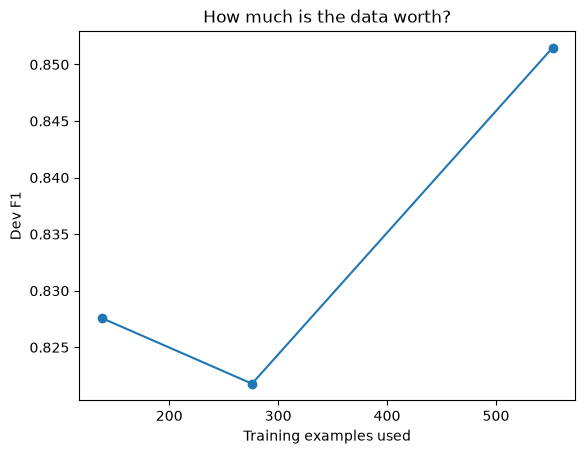

{138: 0.828, 276: 0.822, 552: 0.851}


In [79]:
# YOUR TURN: adapt this to your BEST model, and pick the metric you care about.
fractions = [0.25, 0.50, 1.00]
sizes, scores = [], []
for frac in fractions:
    X_sub = X_train_final.sample(frac=frac, random_state=0)
    y_sub = y_train.loc[X_sub.index]
    if frac == 1.00:
        print(f"Training on {len(X_sub)} examples (the full training set).")
        print(f" data is {X_sub.head}")
    forest_model = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_depth=5, random_state=23)
    forest_model.fit(X_sub, y_sub)

    dev_pred = forest_model.predict(X_dev_final)
    forrest_results.append({
        "n_estimators": n,
        "min_samples_leaf": leaf_size,
        "max_depth": depth,
        "recall": recall_score(y_dev, dev_pred),
        "precision": precision_score(y_dev, dev_pred),
        "f1": f1_score(y_dev, dev_pred),
        "accuracy": accuracy_score(y_dev, dev_pred)
    })

    sizes.append(len(X_sub))
    scores.append(f1_score(y_dev, forest_model.predict(X_dev_final)))

plt.plot(sizes, scores, marker='o')
plt.xlabel('Training examples used')
plt.ylabel('Dev F1')
plt.title('How much is the data worth?')
plt.show()
print(dict(zip(sizes, [round(s, 3) for s in scores])))


Training on 552 examples (the full training set).
 data is <bound method NDFrame.head of      age  trestbps   chol  thalch  oldpeak   ca  sex_Female  sex_Male  \
904   57     130.0  207.0    96.0      1.0  0.0         0.0       1.0   
726   65     150.0  236.0   105.0      0.0  0.0         0.0       1.0   
145   47     108.0  243.0   152.0      0.0  0.0         0.0       1.0   
10    57     140.0  192.0   148.0      0.4  0.0         0.0       1.0   
710   67     145.0  239.0   125.0      0.0  0.0         0.0       1.0   
..   ...       ...    ...     ...      ...  ...         ...       ...   
695   62     150.0  239.0    78.0      2.0  0.0         0.0       1.0   
493   34     140.0  156.0   180.0      0.0  0.0         0.0       1.0   
884   51     130.0  239.0   140.0      0.6  0.0         0.0       1.0   
247   47     110.0  275.0   118.0      1.0  1.0         0.0       1.0   
838   59     125.0  222.0   135.0      2.5  0.0         0.0       1.0   

     cp_asymptomatic  cp_atypical 

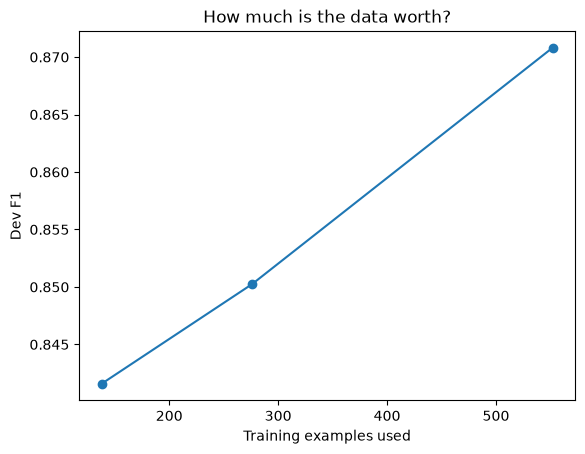

{138: 0.842, 276: 0.85, 552: 0.871}


In [82]:
# YOUR TURN: adapt this to your BEST model, and pick the metric you care about.
fractions = [0.25, 0.50, 1.00]
sizes, scores = [], []
for frac in fractions:
    # Randomly select rows
    X_sub = X_train_final.sample(frac=frac, random_state=0)

    # Restore the original training DataFrame row order
    X_sub = X_sub.loc[
        X_train_final.index[X_train_final.index.isin(X_sub.index)]
    ]

    # Align labels with selected features
    y_sub = y_train.loc[X_sub.index]
    if frac == 1.00:
        print(f"Training on {len(X_sub)} examples (the full training set).")
        print(f" data is {X_sub.head}")
    forest_model = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_depth=5, random_state=23)
    forest_model.fit(X_sub, y_sub)

    dev_pred = forest_model.predict(X_dev_final)
    forrest_results.append({
        "n_estimators": n,
        "min_samples_leaf": leaf_size,
        "max_depth": depth,
        "recall": recall_score(y_dev, dev_pred),
        "precision": precision_score(y_dev, dev_pred),
        "f1": f1_score(y_dev, dev_pred),
        "accuracy": accuracy_score(y_dev, dev_pred)
    })

    sizes.append(len(X_sub))
    scores.append(f1_score(y_dev, forest_model.predict(X_dev_final)))

plt.plot(sizes, scores, marker='o')
plt.xlabel('Training examples used')
plt.ylabel('Dev F1')
plt.title('How much is the data worth?')
plt.show()
print(dict(zip(sizes, [round(s, 3) for s in scores])))


### data ablation while preserving order


---
When you're happy with your experiments, write up your report (see the assignment PDF for the required sections and the Generative AI Use Statement). Questions → Discord `#homework-help`.
